# 02 — Modélisation : prédire l'espérance de vie

Cible : espérance de vie à la naissance. Variables : log(PIB/hab.), électricité, eau potable, fécondité, urbanisation, Internet (la mortalité infantile est exclue : elle entre presque mécaniquement dans le calcul de l'espérance de vie).

Deux protocoles, chacun avec une **référence** à battre :
1. **Temporel** — apprendre sur 2000–2016, tester sur 2017–2024. Références : dernière valeur connue, tendance linéaire par pays. Le choix du modèle se fait sur une validation 2013–2016 (apprentissage 2000–2012), sans regarder le test.
2. **Pays jamais vu** — leave-one-country-out. Référence : moyenne des autres pays la même année.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.precision", 2)
from src.config import COUNTRIES, FOCUS, LABELS
from src.data import load_panel
from src import analysis, plots
panel = load_panel()
countries = panel[~panel.is_aggregate]
from src.model import (make_dataset, evaluate_validation, evaluate_temporal, evaluate_country_holdout,
                       importances, FEATURES, TARGET, HYBRID)
df = make_dataset(panel)
print(len(df), 'observations complètes,', df.iso3.nunique(), 'pays,', df.year.min(), '–', df.year.max())

391 observations complètes, 16 pays, 2000 – 2024


## 1. Sélection sur la validation (2013–2016)

In [2]:
evaluate_validation(df).round(3)

,modele,MAE,RMSE,R2
0,Référence : dernière valeur connue,0.93,1.14,0.95
1,Référence : tendance par pays,0.65,0.82,0.97
2,Régression ridge,3.27,4.28,0.26
3,Forêt aléatoire,2.25,3.08,0.62
4,Tendance par pays + correction ridge,0.63,0.80,0.97


La tendance par pays est déjà une référence très forte. Le modèle hybride (tendance + correction ridge) est le meilleur sur la validation : c'est lui que l'on retient avant de regarder le test.

## 2. Test 2017–2024

In [3]:
temporal, detail = evaluate_temporal(df)
temporal.round(3)

,modele,MAE,RMSE,R2
0,Référence : dernière valeur connue,1.37,1.70,0.87
1,Référence : tendance par pays,1.04,1.40,0.91
2,Régression ridge,3.70,4.39,0.14
3,Forêt aléatoire,2.56,3.42,0.48
4,Tendance par pays + correction ridge,0.99,1.34,0.92


Référence : dernière valeur connue      0.85
Référence : tendance par pays           0.16
Régression ridge                        1.79
Forêt aléatoire                         1.51
Tendance par pays + correction ridge    0.21
Name: MAE Bénin (années), dtype: float64

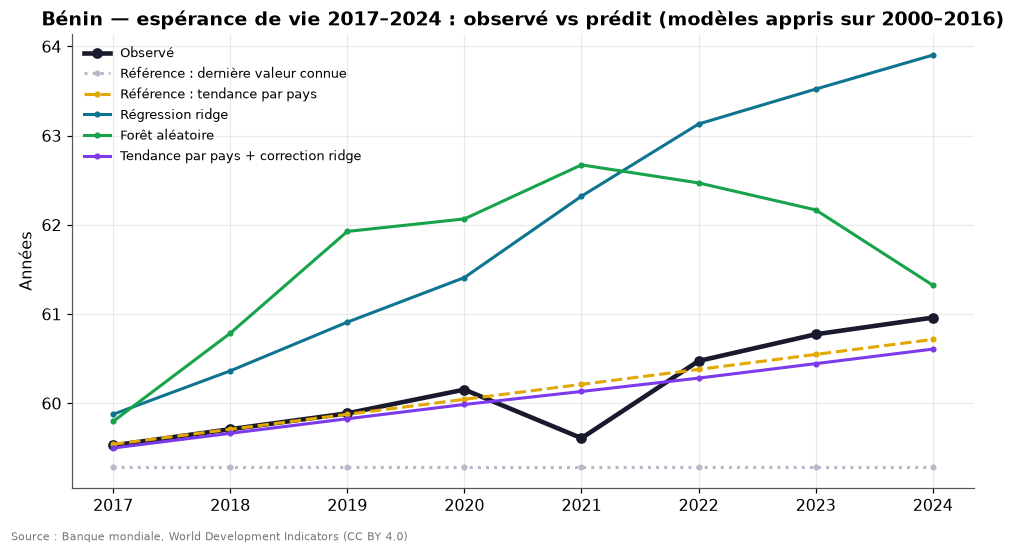

In [4]:
plots.plot_temporal_benin(detail);
ben = detail[detail.iso3 == 'BEN']
(ben[temporal.modele].sub(ben[TARGET], axis=0).abs().mean().rename('MAE Bénin (années)')).round(3)

## 3. Un pays jamais vu

In [5]:
holdout, holdout_detail = evaluate_country_holdout(df)
holdout.round(3)

,modele,MAE,RMSE,R2
0,Référence : moyenne des autres pays (même année),4.19,5.49,0.12
1,Régression ridge,4.22,5.43,0.14
2,Forêt aléatoire,4.57,6.25,-0.14


In [6]:
err = holdout_detail.assign(erreur=lambda d: (d['Régression ridge'] - d[TARGET]).abs())
err.groupby('country').erreur.mean().sort_values(ascending=False).round(2).rename('MAE ridge par pays').to_frame()

,MAE ridge par pays
country,
Mauritanie,11.46
Nigeria,9.52
Niger,8.11
Cabo Verde,7.31
Sierra Leone,5.22
Côte d'Ivoire,4.51
Gambie,3.39
Sénégal,3.13
Guinée,2.63


Prédire le **niveau** d'espérance de vie d'un pays à partir de ses seuls indicateurs ne fait pas mieux que la moyenne des autres pays : les écarts entre pays tiennent à des facteurs absents des données (systèmes de santé, conflits, épidémies, paludisme…).

## 4. Diagnostic du modèle hybride

,variable,coef_correction_standardise,importance_permutation_mae
0,Internet,-3.30e-02,1.40e-02
1,Accès à l'électricité,-1.60e-02,2.00e-03
2,Fécondité,1.20e-02,-0.00e+00
3,Population urbaine,-9.00e-03,-1.00e-03
4,Eau potable de base,2.40e-02,-2.00e-03
5,log(PIB par habitant),4.00e-02,-2.00e-03


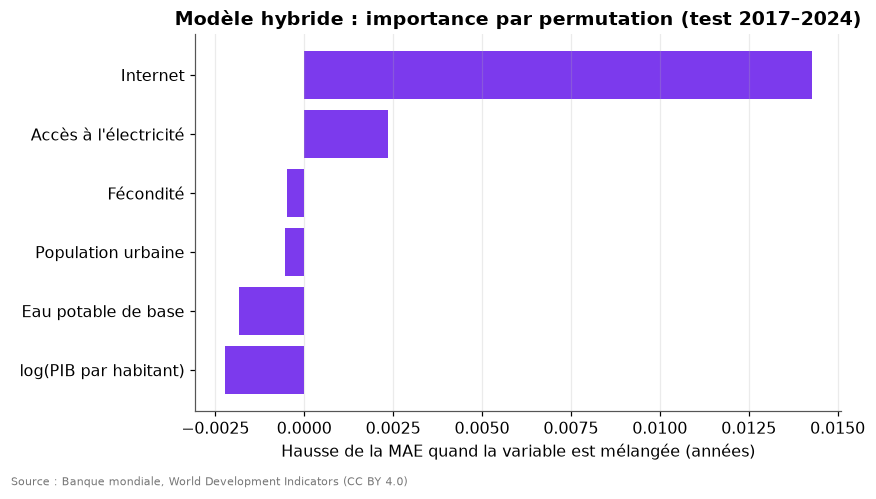

In [7]:
imp = importances(df)
plots.plot_importance(imp);
imp.round(3)

## Conclusions
- Pour la prévision à court terme, **la trajectoire passée du pays** est l'information la plus utile : la tendance par pays est difficile à battre.
- Le modèle hybride ne l'améliore que légèrement en moyenne, et pas pour le Bénin ; la correction repose surtout sur Internet, extrapolé hors de la plage d'apprentissage. Ce gain ne doit pas être sur-interprété.
- Les modèles « en niveau » (ridge, forêt aléatoire) échouent à généraliser dans le temps et entre pays.
- Limites : 16 pays seulement, données estimées et révisées par la Banque mondiale, choc de la COVID-19 (2020–2021) dans le test, corrélation ≠ causalité.